# Graph construction with OpenAI embeddings
This notebook loads 99 court-case structures, visualizes one argument graph, and compares cases 116075685 and 116125191 using argument-type masking, cosine similarity, structural propagation (alpha=0.5, tolerance=1e-6, at most 100 iterations), and the top five matches per node.

Set OPENAI_API_KEY in the Jupyter kernel environment before running all cells. Text is sent to the OpenAI embeddings API. The default is text-embedding-3-large with 3072 dimensions. Successful batches are cached locally by model, dimensions, and text hash; repeated runs reuse them. No local BGE model or GPU is required.

Both node texts and relation justifications are embedded, as in the original algorithm. Structural propagation uses unweighted adjacency; relation embeddings remain graph attributes and do not affect its score. Results are written to result_openai.npy with node order and configuration in result_openai.json. Scores will differ from BGE; reproduction means retaining the algorithm, not matching its numerical results.

API reference: https://developers.openai.com/api/reference/ruby/resources/embeddings/methods/create

Run status: Data loading (99 documents), sample graph visualization, and cosine-reference checks passed. The OpenAI embedding and downstream similarity/matching run is pending API credentials and explicit data-transfer approval. No new OpenAI result has been produced.

In [52]:
import networkx as nx
import pandas as pd
import numpy as np
from pathlib import Path
import json

In [53]:
search_roots = (Path.cwd(), *Path.cwd().parents)
NOTEBOOK_DIR = next(
    base for root in search_roots
    for base in (root, root / "src/legal_data_doc_parts/paragraph_analysis")
    if (base / "document_data_parsing").is_dir()
)
JSON_STRUCTURE_PATH = str(NOTEBOOK_DIR / "document_data_parsing/{doc_id}.json")

In [54]:
paragraph_dataset_mini = [
    "116062204", "116075685", "116080900", "116084352", "116084886", "116099338", "116102314", "116105977", "116106432", "116109598", "116110555", "116116081", "116118921", "116120654", "116121714", "116125191", "116126076", "116127831", "116141779", "116142769", "116149190", "116150283", "116167789", "116168634", "116170057", "116170822", "116192026", "116194637", "116196887", "116197578", "116199866", "116204676", "116213690", "116214232", "116220471", "116221948", "116226431", "116229939", "116232414", "116233794", "116245112", "116246991", "116248468", "116252607", "116253514", "116256069", "116257159", "116259036", "116260246", "116261015", "116261263", "116270112", "116277632", "116278949", "116283678", "116285648", "116289180", "116308208", "116310154", "116320626", "116321603", "116336690", "116339406", "116344031", "116350541", "116350825", "116358099", "116359089", "116376162", "116377931", "116385451", "116398308", "116410200", "116410462", "116414218", "116432495", "116434259", "116442566", "116462199", "116588653", "116681882", "116764649", "116780853", "116790074", "116794466", "116972204", "117069850", "117125134", "117130242", "117230819", "117251852", "117420480", "117440182", "117456818", "117460145", "117464049", "117489745", "117516936", "117556435"
]

In [55]:
from pathlib import Path
import json

In [56]:
def read_json_file(path: str):
    with open(path, "r") as doc_file:
        doc_file_contents = json.loads(doc_file.read())

    return doc_file_contents

In [57]:
def read_structures(doc_list: list[str]) -> dict:
    docs = {}
    for doc_id in doc_list:
        doc_path = JSON_STRUCTURE_PATH.format(doc_id=doc_id)
        doc_json_contents = read_json_file(doc_path)
        docs[doc_id] = doc_json_contents

    return docs

In [58]:
doc_args = read_structures(paragraph_dataset_mini)
len(doc_args)

99

In [59]:
print(f"Loaded {len(doc_args)} document structures.")

Loaded 99 document structures.


## Extracting premises and conclusions from the doc structure


In [60]:
import jsonpath

In [61]:
def compose_dataframe(doc_dict: dict[str, dict]):
    df = pd.DataFrame(columns=["doc_id", "arg_id", "arg_text", "arg_type", "arg_argtype"])
    for doc_id, doc_contents in doc_dict.items():
        doc_df_dict = {}
        orig_arg_id = jsonpath.findall("$.result.components[*].id", doc_contents)
        orig_arg_text = jsonpath.findall("$.result.components[*].source_span.text", doc_contents)
        orig_arg_type = jsonpath.findall("$.result.components[*].type", doc_contents)
        orig_arg_argtype = jsonpath.findall("$.result.components[*].argumentative_role", doc_contents)

        assert len(orig_arg_text) == len(orig_arg_type) == len(orig_arg_argtype)
        doc_id_list = [doc_id for _ in range(len(orig_arg_text))]

        doc_df_dict["doc_id"] = doc_id_list
        doc_df_dict["arg_id"] = orig_arg_id
        doc_df_dict["arg_text"] = orig_arg_text
        doc_df_dict["arg_type"] = orig_arg_type
        doc_df_dict["arg_argtype"] = orig_arg_argtype
        df = pd.concat([df, pd.DataFrame(doc_df_dict)])

    return df

In [62]:
arguments_df = compose_dataframe(doc_args)
arguments_df.head()

,doc_id,arg_id,arg_text,arg_type,arg_argtype
0,116062204,P17,Відповідно до витягу з наказу військової части...,PREMISE,BASE_PREMISE
1,116062204,P18,Відповідно до витягу з наказу військової части...,PREMISE,BASE_PREMISE
2,116062204,P19,"Згідно зі ст.ст. 11, 16, 49 Статуту внутрішньо...",PREMISE,BASE_PREMISE
3,116062204,P20,"Відповідно до ст.ст. 1, 4, 6 Дисциплінарного с...",PREMISE,BASE_PREMISE
4,116062204,C21,"Проте, рядовий ОСОБА_5 та молодший сержант ОСО...",CLAIM,INTERMEDIATE_CONCLUSION


## Extracting edges from the document

In [63]:
def compose_relations_df(doc_dict: dict[str, dict]):
    df = pd.DataFrame(columns=["doc_id", "rel_id", "source", "target", "relation", "support_structure", "confidence", "justification"])
    for doc_id, doc_contents in doc_dict.items():
        relation_id = jsonpath.findall("$.result.relations[*].id", doc_contents)
        relation_source = jsonpath.findall("$.result.relations[*].source", doc_contents)
        relation_target = jsonpath.findall("$.result.relations[*].target", doc_contents)
        relation_relation = jsonpath.findall("$.result.relations[*].relation", doc_contents)
        relation_support = jsonpath.findall("$.result.relations[*].support_structure", doc_contents)
        relation_confidence = jsonpath.findall("$.result.relations[*].confidence", doc_contents)
        relation_justification = jsonpath.findall("$.result.relations[*].justification", doc_contents)

        relations_df_dict = {
            "doc_id": [doc_id for _ in range(len(relation_id))],
            "rel_id": relation_id,
            "source": relation_source,
            "target": relation_target,
            "relation": relation_relation,
            "support_structure": relation_support,
            "confidence": relation_confidence,
            "justification": relation_justification,
        }
        df = pd.concat([df, pd.DataFrame(relations_df_dict)])

    return df

In [64]:
relations_df = compose_relations_df(doc_args)

In [65]:
relations_df.head()

,doc_id,rel_id,source,target,relation,support_structure,confidence,justification
0,116062204,E01,P23,C26,SUPPORT,CONVERGENT,0.9,Опис дій обвинувачених у період воєнного стану...
1,116062204,E02,P24,C26,SUPPORT,CONVERGENT,0.95,Детальний опис таємного викрадення майна є фак...
2,116062204,E03,C21,C26,SUPPORT,CONVERGENT,0.78,Висновок про умисний характер дій та порушення...
3,116062204,E04,P28a,C37,SUPPORT,CONVERGENT,0.86,Визнання вини та пояснення обставин ОСОБА_5 пі...
4,116062204,E05,P30a,C37,SUPPORT,CONVERGENT,0.86,Визнання вини та пояснення обставин ОСОБА_6 пі...


## Graph construction

In [66]:
import matplotlib.pyplot as plt

In [67]:
relations_df["doc_id"].unique(), arguments_df["doc_id"].unique()

(array(['116062204', '116075685', '116080900', '116084352', '116084886',
        '116099338', '116102314', '116105977', '116106432', '116109598',
        '116110555', '116116081', '116118921', '116120654', '116121714',
        '116125191', '116126076', '116127831', '116141779', '116142769',
        '116149190', '116167789', '116168634', '116170057', '116170822',
        '116192026', '116194637', '116196887', '116197578', '116199866',
        '116204676', '116213690', '116214232', '116220471', '116221948',
        '116226431', '116229939', '116232414', '116233794', '116245112',
        '116246991', '116248468', '116252607', '116253514', '116256069',
        '116257159', '116259036', '116260246', '116261015', '116261263',
        '116277632', '116278949', '116283678', '116285648', '116289180',
        '116308208', '116310154', '116320626', '116321603', '116336690',
        '116339406', '116344031', '116350541', '116350825', '116358099',
        '116359089', '116376162', '116377931', '116

In [68]:
arg_sampled_df = arguments_df[arguments_df["doc_id"] == "116084352"]
rel_sampled_df = relations_df[relations_df["doc_id"] == "116084352"]
arg_sampled_df, rel_sampled_df

(       doc_id arg_id                                           arg_text  \
 0   116084352    P01  ОСОБА_4  28.06.2023 в нічний час, діючи разом ...   
 1   116084352    P02  В подальшому, ОСОБА_4 та особа, яка не є суб`є...   
 2   116084352    C01  Тобто,  ОСОБА_4 скоїв таємне викрадення чужого...   
 3   116084352    P03  Також  ОСОБА_4 разом із особою, яка не є суб`є...   
 4   116084352    P04  В подальшому, ОСОБА_4 та особа, яка не є суб`є...   
 5   116084352    C02  Тобто ОСОБА_4 скоїв таємне викрадення чужого м...   
 6   116084352    P05  Також ОСОБА_4 , діючи разом із особою, яка не ...   
 7   116084352    P06  В подальшому, ОСОБА_4 та особа, яка не є суб`є...   
 8   116084352    C03  Тобто ОСОБА_4 скоїв таємне викрадення чужого м...   
 9   116084352    C04  ОСОБА_4 скоїв таємне викрадення чужого майна (...   
 10  116084352    P07  Обвинувачений  ОСОБА_4 у судовому засіданні св...   
 11  116084352    P08  Крім визнання своєї вини обвинуваченим, його в...   
 12  1160843

In [69]:
bi_legal_G = nx.DiGraph()

for row in arg_sampled_df.itertuples(index=False):
    bi_legal_G.add_node(
        row.arg_id,
        arg_type=row.arg_type,
        argumentative_role=row.arg_argtype,
        text=row.arg_text,
    )

for row in rel_sampled_df.itertuples(index=False):
    bi_legal_G.add_edge(
        row.source,
        row.target,
        relation=row.relation,
        confidence=float(row.confidence),
    )

In [70]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def _hierarchical_layout(graph):
    positions = {}
    y_offset = 0.0
    components = sorted(nx.weakly_connected_components(graph), key=len, reverse=True)

    for component_nodes in components:
        component = graph.subgraph(component_nodes)
        if nx.is_directed_acyclic_graph(component):
            levels = [list(level) for level in nx.topological_generations(component)]
        else:
            levels = [list(component.nodes)]

        component_height = max(len(level) for level in levels)
        component_center = y_offset + (component_height - 1) / 2

        for depth, level in enumerate(levels):
            y_values = (
                np.linspace(y_offset, y_offset + component_height - 1, len(level))
                if len(level) > 1
                else [component_center]
            )
            for node, y_value in zip(sorted(level), y_values):
                positions[node] = (depth * 3.2, float(y_value))

        y_offset += component_height + 2.0

    return positions


def visualize_graph(G, *, show_isolates=False):
    graph = G if show_isolates else G.subgraph(
        [node for node in G if G.degree(node) > 0]
    ).copy()

    if graph.number_of_nodes() == 0:
        raise ValueError("The graph has no connected nodes to display.")

    node_colors = [
        "#4C78A8" if graph.nodes[node].get("arg_type") == "PREMISE" else "#F2CF5B"
        for node in graph
    ]
    edge_colors = [
        "#D62728" if data.get("relation") == "ATTACK" else "#59A14F"
        for _, _, data in graph.edges(data=True)
    ]
    edge_widths = [
        0.8 + 2.2 * data.get("confidence", 0.5)
        for _, _, data in graph.edges(data=True)
    ]
    pos = _hierarchical_layout(graph)

    fig, ax = plt.subplots(figsize=(20, 14), constrained_layout=True)
    nx.draw_networkx_nodes(
        graph,
        pos,
        node_color=node_colors,
        node_size=900,
        edgecolors="white",
        linewidths=1.2,
        ax=ax,
    )
    nx.draw_networkx_edges(
        graph,
        pos,
        edge_color=edge_colors,
        width=edge_widths,
        alpha=0.65,
        arrows=True,
        arrowsize=16,
        arrowstyle="-|>",
        connectionstyle="arc3,rad=0.04",
        min_source_margin=12,
        min_target_margin=12,
        ax=ax,
    )
    nx.draw_networkx_labels(graph, pos, font_size=8, font_weight="bold", ax=ax)

    legend_items = [
        Patch(facecolor="#4C78A8", label="Premise"),
        Patch(facecolor="#F2CF5B", label="Claim"),
        Line2D([0], [0], color="#59A14F", lw=2, label="Support"),
        Line2D([0], [0], color="#D62728", lw=2, label="Attack"),
    ]
    ax.legend(handles=legend_items, loc="upper left", frameon=True)
    ax.set_title(
        f"Argument graph — {graph.number_of_nodes()} nodes, "
        f"{graph.number_of_edges()} relations",
        fontsize=16,
        pad=16,
    )
    ax.margins(0.08)
    ax.axis("off")
    plt.show()

    return graph

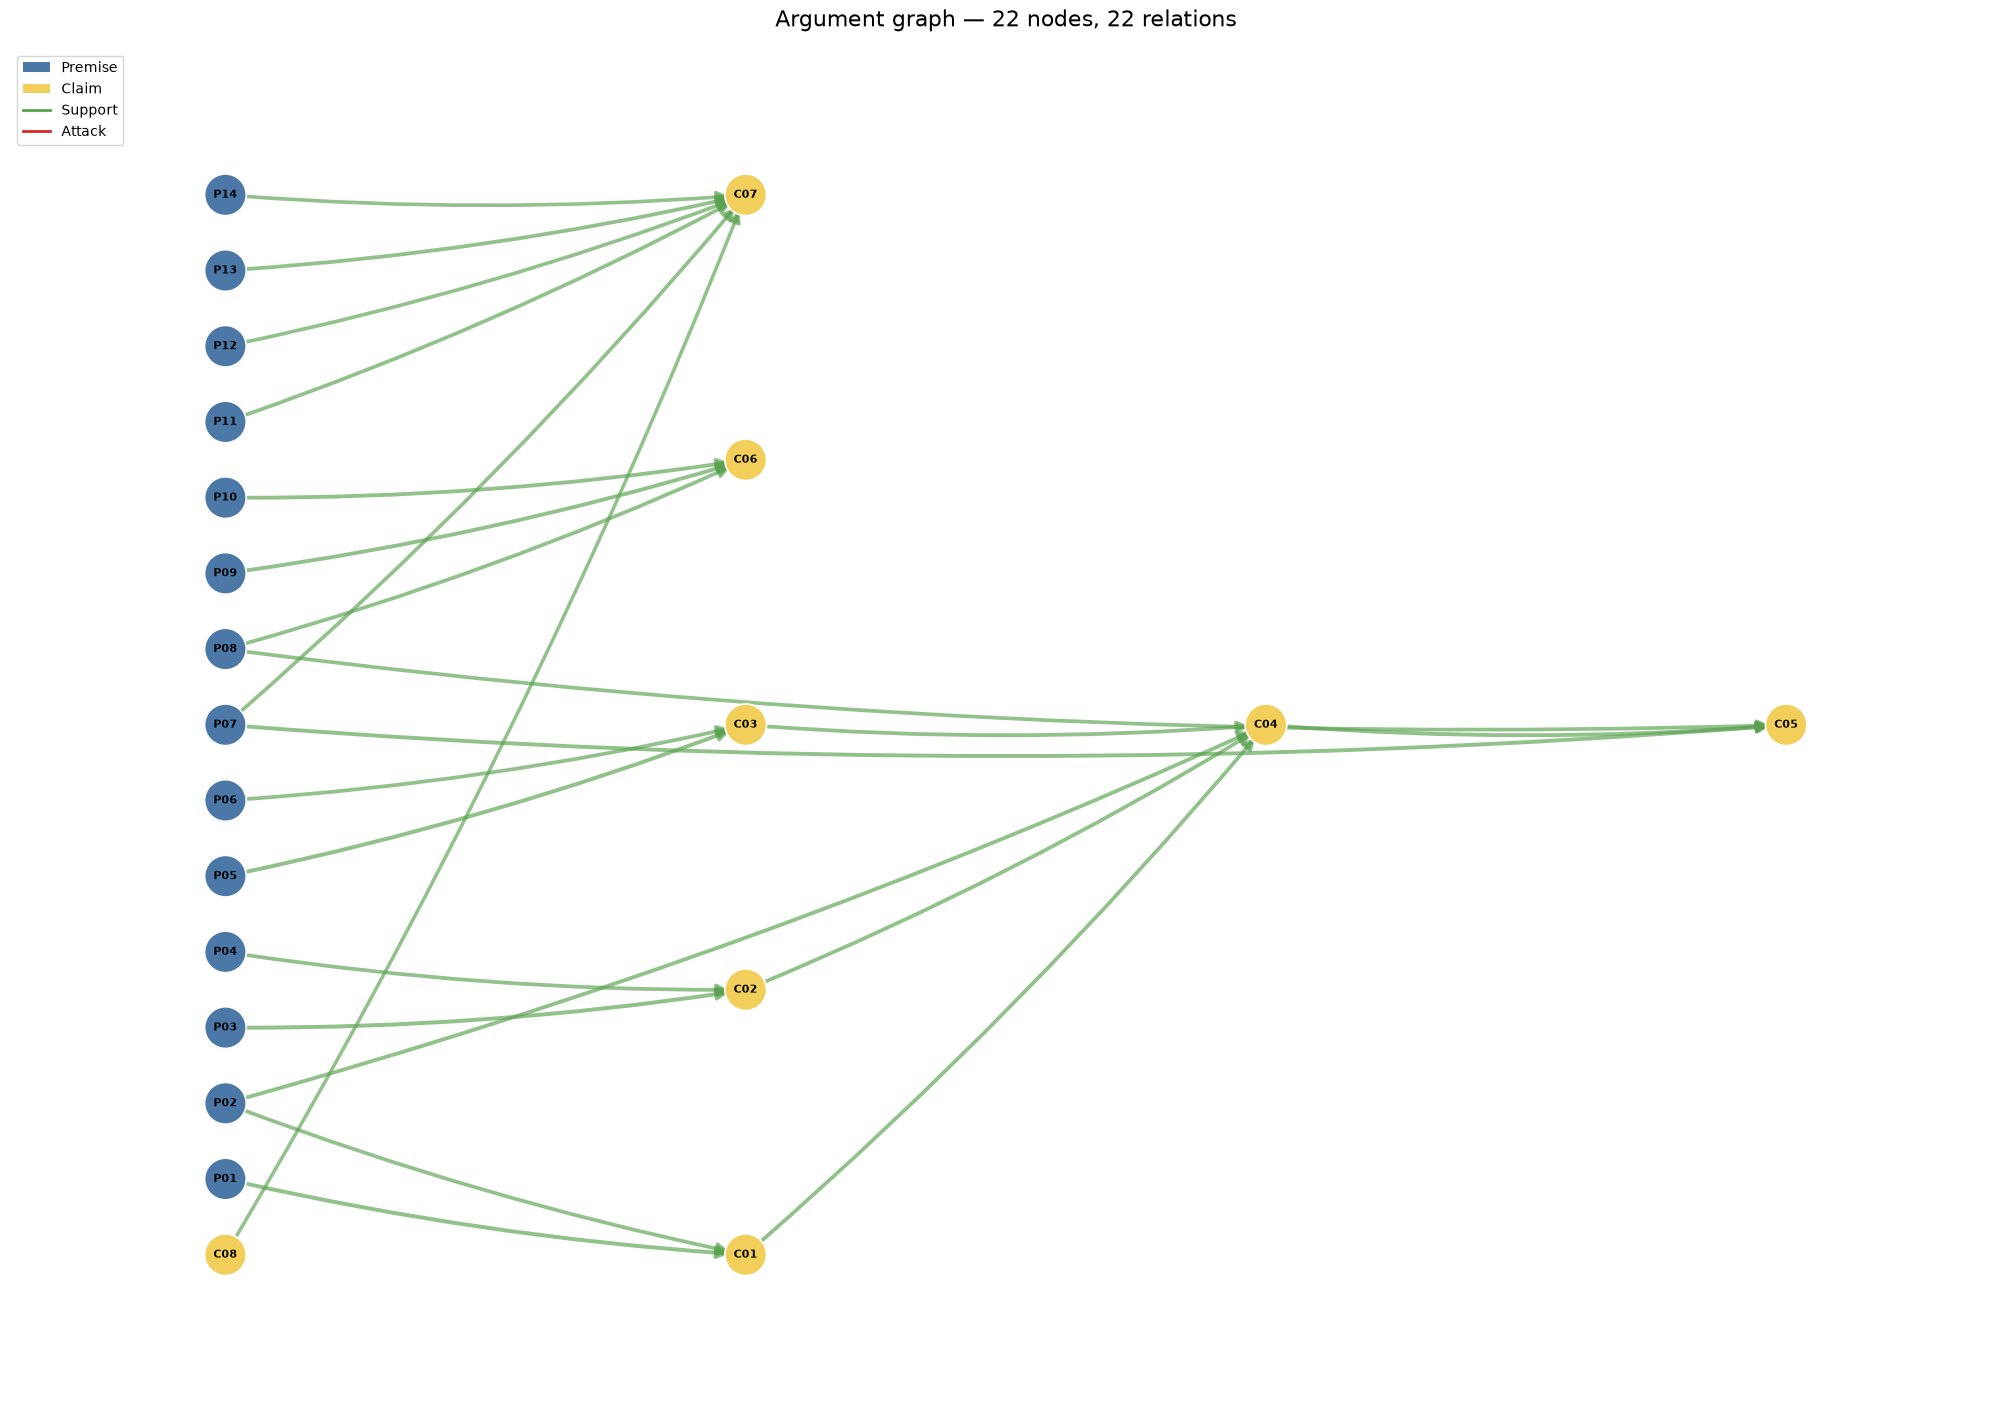

In [71]:
displayed_graph = visualize_graph(bi_legal_G)

In [72]:
# bi_legal_G.add_edges_from([(rel[0] + rel[1], rel[0] + rel[2]) for rel in relations_df[arguments_df["doc_id"] == "116062204"][["doc_id", "source", "target"]].values.tolist()])
# bi_legal_G.add_nodes_from([arg[0] + "." + arg[1] for arg in arguments_df[arguments_df["doc_id"] == "116062204"][["doc_id", "arg_id"]].values.tolist()])


# Merging two graphs

In [73]:
import hashlib
import os
import time
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError

In [74]:
EMBEDDING_MODEL = "text-embedding-3-large"
EMBEDDING_DIMENSIONS = 3072
EMBEDDING_BATCH_SIZE = 16
EMBEDDING_CACHE_DIR = NOTEBOOK_DIR / "doc_artifacts" / "openai_embeddings"
# Conservative byte bound avoids exceeding the token limit without a tokenizer.
# Longer inputs fail explicitly; no argument text is silently truncated.
MAX_INPUT_BYTES = 8191

In [75]:
class OpenAIArgumentEncoder:
    def __init__(self, model, dimensions, cache_dir):
        self.model = model
        self.dimensions = dimensions
        self.cache_dir = Path(cache_dir)

    def _cache_path(self, text):
        payload = json.dumps([self.model, self.dimensions, text], ensure_ascii=False)
        return self.cache_dir / (hashlib.sha256(payload.encode("utf-8")).hexdigest() + ".npy")

    def _validate_vector(self, vector):
        vector = np.asarray(vector, dtype=np.float32)
        if vector.shape != (self.dimensions,) or not np.isfinite(vector).all():
            raise ValueError("Invalid embedding shape or non-finite values.")
        if np.linalg.norm(vector) == 0:
            raise ValueError("Received a zero embedding.")
        return vector

    def _request(self, texts):
        api_key = os.environ.get("OPENAI_API_KEY", "").strip()
        if not api_key:
            raise RuntimeError("Set OPENAI_API_KEY in the Jupyter kernel environment and rerun.")
        body = json.dumps({
            "model": self.model, "dimensions": self.dimensions,
            "input": texts, "encoding_format": "float",
        }).encode("utf-8")
        request = Request(
            "https://api.openai.com/v1/embeddings", data=body,
            headers={"Authorization": "Bearer " + api_key, "Content-Type": "application/json"},
            method="POST",
        )
        for attempt in range(5):
            try:
                with urlopen(request, timeout=60) as response:
                    result = json.load(response)
                data = sorted(result["data"], key=lambda item: item["index"])
                if [item["index"] for item in data] != list(range(len(texts))):
                    raise ValueError("Embedding response indices do not match the input batch.")
                return [self._validate_vector(item["embedding"]) for item in data]
            except HTTPError as exc:
                if exc.code not in (429, 500, 502, 503, 504) or attempt == 4:
                    raise RuntimeError(f"OpenAI embeddings request failed (HTTP {exc.code}).") from None
                delay = min(30, 2 ** attempt)
                exc.close()
            except (URLError, TimeoutError):
                if attempt == 4:
                    raise RuntimeError("OpenAI embeddings connection failed after five attempts.") from None
                delay = min(30, 2 ** attempt)
            time.sleep(delay)

    def encode(self, texts, batch_size=EMBEDDING_BATCH_SIZE, show_progress_bar=True):
        single = isinstance(texts, str)
        texts = [texts] if single else list(texts)
        if not 1 <= batch_size <= 16:
            raise ValueError("batch_size must be between 1 and 16.")
        for index, text in enumerate(texts):
            if not isinstance(text, str) or not text.strip():
                raise ValueError(f"Input {index} must be nonempty text.")
            if len(text.encode("utf-8")) > MAX_INPUT_BYTES:
                raise ValueError(f"Input {index} exceeds the conservative {MAX_INPUT_BYTES}-byte limit; use token-aware chunking before embedding.")
        vectors = {}
        missing = []
        for text in dict.fromkeys(texts):
            path = self._cache_path(text)
            if path.exists():
                vectors[text] = self._validate_vector(np.load(path, allow_pickle=False))
            else:
                missing.append(text)
        for start in range(0, len(missing), batch_size):
            batch = missing[start:start + batch_size]
            embeddings = self._request(batch)
            self.cache_dir.mkdir(parents=True, exist_ok=True)
            for text, vector in zip(batch, embeddings, strict=True):
                path = self._cache_path(text)
                temporary = path.with_suffix(".tmp")
                with temporary.open("wb") as cache_file:
                    np.save(cache_file, vector, allow_pickle=False)
                temporary.replace(path)
                vectors[text] = vector
            if show_progress_bar:
                print(f"Embedded {min(start + batch_size, len(missing))}/{len(missing)} uncached texts", flush=True)
        result = np.stack([vectors[text] for text in texts]) if texts else np.empty((0, self.dimensions), dtype=np.float32)
        return result[0] if single else result

In [85]:
argument_encoder = OpenAIArgumentEncoder(
    EMBEDDING_MODEL, EMBEDDING_DIMENSIONS, EMBEDDING_CACHE_DIR
)

print(f"Encoder: {EMBEDDING_MODEL}, dimensions: {EMBEDDING_DIMENSIONS}")
print(f"API key configured: {bool(os.environ.get('OPENAI_API_KEY'))}")

Encoder: text-embedding-3-large, dimensions: 3072
API key configured: True


In [86]:
def construct_case_graph(doc_id: str):
    arg_sampled_df = arguments_df[arguments_df["doc_id"] == doc_id]
    rel_sampled_df = relations_df[relations_df["doc_id"] == doc_id]
    if arg_sampled_df.empty:
        raise ValueError(f"No arguments for document {doc_id}.")
    ids = set(arg_sampled_df["arg_id"])
    if len(ids) != len(arg_sampled_df):
        raise ValueError(f"Duplicate argument IDs in {doc_id}.")
    endpoints = set(rel_sampled_df["source"]) | set(rel_sampled_df["target"])
    if endpoints - ids:
        raise ValueError(f"Dangling relation endpoints in {doc_id}: {endpoints - ids}")
    texts = arg_sampled_df["arg_text"].tolist() + rel_sampled_df["justification"].tolist()
    embeddings = argument_encoder.encode(texts)
    node_count = len(arg_sampled_df)
    case_G = nx.DiGraph(embedding_model=EMBEDDING_MODEL, embedding_dimensions=EMBEDDING_DIMENSIONS)
    for row, embedding in zip(arg_sampled_df.itertuples(index=False), embeddings[:node_count], strict=True):
        case_G.add_node(
            doc_id + "." + row.arg_id, arg_type=row.arg_type,
            argumentative_role=row.arg_argtype, text=row.arg_text,
            embedding=embedding.tolist(),
        )
    for row, embedding in zip(rel_sampled_df.itertuples(index=False), embeddings[node_count:], strict=True):
        case_G.add_edge(
            doc_id + "." + row.source, doc_id + "." + row.target,
            relation=row.relation, confidence=float(row.confidence),
            relation_embedding=embedding.tolist(),
        )
    return case_G

In [87]:
case_1_G = construct_case_graph("116075685")
case_2_G = construct_case_graph("116125191")

Embedded 16/124 uncached texts
Embedded 32/124 uncached texts
Embedded 48/124 uncached texts
Embedded 64/124 uncached texts
Embedded 80/124 uncached texts
Embedded 96/124 uncached texts
Embedded 112/124 uncached texts
Embedded 124/124 uncached texts
Embedded 16/63 uncached texts
Embedded 32/63 uncached texts
Embedded 48/63 uncached texts
Embedded 63/63 uncached texts


In [88]:
arguments_df[arguments_df["doc_id"] == "116125191"].shape, arguments_df[arguments_df["doc_id"] == "116075685"].shape

((38, 5), (132, 5))

#### Distance for embeddings function

In [89]:
def process_distances(embeddings_1, embeddings_2, global_batch_size):
    x = np.asarray(embeddings_1, dtype=np.float32)
    y = np.asarray(embeddings_2, dtype=np.float32)
    if x.ndim != 2 or y.ndim != 2 or x.shape[1] != y.shape[1]:
        raise ValueError("Expected embedding matrices with matching dimensions.")
    if global_batch_size < 1:
        raise ValueError("global_batch_size must be positive.")
    x = x / np.maximum(np.linalg.norm(x, axis=1, keepdims=True), 1e-12)
    y = y / np.maximum(np.linalg.norm(y, axis=1, keepdims=True), 1e-12)
    distances = np.empty((len(x), len(y)), dtype=np.float32)
    for start in range(0, len(x), global_batch_size):
        distances[start:start + global_batch_size] = x[start:start + global_batch_size] @ y.T
    return distances

Check if the function works correctly

In [90]:
A = np.array([
    [1.0, 0.0],
    [0.0, 1.0],
    [1.0, 1.0],
])

B = np.array([
    [1.0, 0.0],
    [0.0, 1.0],
    [-1.0, 0.0],
    [1.0, 1.0],
])

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

S = A_norm @ B_norm.T

S

array([[ 1.        ,  0.        , -1.        ,  0.70710678],
       [ 0.        ,  1.        ,  0.        ,  0.70710678],
       [ 0.70710678,  0.70710678, -0.70710678,  1.        ]])

In [91]:
np.testing.assert_allclose(process_distances(A, B, 2), S, atol=1e-6)
print("Cosine similarity matches the reference calculation.")

Cosine similarity matches the reference calculation.


## Cross-graph similarity

In [92]:
case_1_G.nodes

NodeView(('116075685.P01', '116075685.P02', '116075685.P03', '116075685.C01', '116075685.P04', '116075685.P05', '116075685.P06', '116075685.C02', '116075685.P07', '116075685.P08', '116075685.P09', '116075685.C03', '116075685.P10', '116075685.P11', '116075685.P12', '116075685.C04', '116075685.P13', '116075685.P14', '116075685.P15', '116075685.C05', '116075685.P16', '116075685.P17', '116075685.P18', '116075685.C06', '116075685.P19', '116075685.P20', '116075685.P21', '116075685.C07', '116075685.P22', '116075685.P23', '116075685.P24', '116075685.C08', '116075685.P25', '116075685.P26', '116075685.P27', '116075685.C09', '116075685.P28', '116075685.P29', '116075685.P30', '116075685.C10', '116075685.C11', '116075685.C12', '116075685.C13', '116075685.C14', '116075685.C15', '116075685.P31', '116075685.P32', '116075685.P33', '116075685.C16', '116075685.C17', '116075685.C18', '116075685.C19', '116075685.C20', '116075685.C21', '116075685.C22', '116075685.C23', '116075685.C24', '116075685.C25', '116

In [93]:
def transition_matrix(A):
    degree = A.sum(axis=1)
    degree[degree == 0] = 1
    return A / degree[:, None]

In [94]:
mask = np.zeros(shape=(case_1_G.number_of_nodes(), case_2_G.number_of_nodes()))
for i, u in enumerate(case_1_G.nodes):
    for j, v in enumerate(case_2_G.nodes):
        if case_1_G.nodes[u]["arg_type"] == case_2_G.nodes[v]["arg_type"]:
            mask[i, j] = 1

In [95]:
def cross_graph_similarity(G1: nx.Graph, G2: nx.Graph, alpha, tol=1e-6, mask=None):
    emb1 = np.stack([
        G1.nodes[node]["embedding"]
        for node in G1.nodes
    ])
    emb2 = np.stack([
        G2.nodes[node]["embedding"]
        for node in G2.nodes
    ])
    # S - current belief that node i corresponds to j
    S_0 = process_distances(emb1, emb2, 1)

    if mask is not None:
        S_0 *= mask

    adj_1 = nx.to_numpy_array(G1)
    adj_2 = nx.to_numpy_array(G2)

    p_1 = transition_matrix(adj_1)
    p_2 = transition_matrix(adj_2)

    S = S_0.copy()
    for iteration in range(100):
        S_struct = p_1.T @ S @ p_2

        max_val = S_struct.max()
        if max_val > 0:
            S_struct = S_struct / max_val

        S_new = alpha * S_struct + (1 - alpha) * S_0

        print(f"Iteration -> {iteration}, with changes -> {np.linalg.norm(S_new - S)}")

        if mask is not None:
            S_new *= mask

        if np.linalg.norm(S_new - S) < tol:
            S = S_new
            break

        S = S_new
    return S

In [104]:
graph_sim = cross_graph_similarity(case_1_G, case_2_G, alpha=0.2, mask=mask)

Iteration -> 0, with changes -> 3.6027125633112886
Iteration -> 1, with changes -> 0.001817254325297188
Iteration -> 2, with changes -> 2.4507264310959922e-11


In [105]:
assert graph_sim.shape == (case_1_G.number_of_nodes(), case_2_G.number_of_nodes())
assert np.isfinite(graph_sim).all()
assert np.all(graph_sim[mask == 0] == 0)
np.save(NOTEBOOK_DIR / "result_openai.npy", graph_sim)
metadata = {
    "model": EMBEDDING_MODEL, "dimensions": EMBEDDING_DIMENSIONS,
    "graph1_nodes": list(case_1_G), "graph2_nodes": list(case_2_G),
    "alpha": 0.5, "tolerance": 1e-6, "max_iterations": 100,
    "same_type_only": True,
}
(NOTEBOOK_DIR / "result_openai.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(f"Saved OpenAI similarity matrix: {graph_sim.shape}")

Saved OpenAI similarity matrix: (132, 38)


In [106]:
def top_matches(
    G1: nx.Graph,
    G2: nx.Graph,
    S: np.ndarray,
    top_k: int = 10,
    same_type_only: bool = True,
):
    """Return up to top_k candidates per source node, ranked by similarity."""
    nodes1 = list(G1.nodes)
    nodes2 = list(G2.nodes)

    if S.shape != (len(nodes1), len(nodes2)):
        raise ValueError("S must have one row per G1 node and one column per G2 node")
    if not isinstance(top_k, (int, np.integer)) or top_k < 0:
        raise ValueError("top_k must be a non-negative integer")

    results = []
    for i, node1 in enumerate(nodes1):
        type1 = G1.nodes[node1].get("arg_type")
        candidates = []

        for j, node2 in enumerate(nodes2):
            type2 = G2.nodes[node2].get("arg_type")
            if same_type_only and (type1 is None or type2 is None or type1 != type2):
                continue

            candidates.append({
                "graph1_node": node1,
                "graph1_text": G1.nodes[node1].get("text"),
                "graph1_type": type1,
                "graph2_node": node2,
                "graph2_text": G2.nodes[node2].get("text"),
                "graph2_type": type2,
                "similarity": float(S[i, j]),
            })

        candidates.sort(key=lambda candidate: candidate["similarity"], reverse=True)
        for rank, candidate in enumerate(candidates[:top_k], start=1):
            results.append({**candidate, "rank": rank})

    return results

In [107]:
matches = top_matches(case_1_G, case_2_G, graph_sim, top_k=5)

In [108]:
matches.sort(key=lambda entry: entry.get("similarity", 0), reverse=True)

In [109]:
pd.DataFrame(matches).head(20)

,graph1_node,graph1_text,graph1_type,graph2_node,graph2_text,graph2_type,similarity,rank
0,116075685.C24,"...обставиною, що пом`якшує покарання обвинува...",CLAIM,116125191.C05,"Обставинами, що у відповідності із статтею 66 ...",CLAIM,0.663480,1
1,116075685.C10,"1.20. Отже, ОСОБА_5 учинив злочин, передбачени...",CLAIM,116125191.C02,Своїми діями обвинувачена ОСОБА_3 вчинила крим...,CLAIM,0.588378,1
2,116075685.C66,"1.20. Отже, ОСОБА_5 учинив злочин, передбачени...",CLAIM,116125191.C02,Своїми діями обвинувачена ОСОБА_3 вчинила крим...,CLAIM,0.588378,1
3,116075685.C09,"1.18. Отже, ОСОБА_5 учинив злочин, передбачени...",CLAIM,116125191.C02,Своїми діями обвинувачена ОСОБА_3 вчинила крим...,CLAIM,0.572935,1
4,116075685.C62,"1.18. Отже, ОСОБА_5 учинив злочин, передбачени...",CLAIM,116125191.C02,Своїми діями обвинувачена ОСОБА_3 вчинила крим...,CLAIM,0.572935,1
5,116075685.C02,"1.4. Отже, ОСОБА_5 учинив злочин, передбачений...",CLAIM,116125191.C02,Своїми діями обвинувачена ОСОБА_3 вчинила крим...,CLAIM,0.568465,1
6,116075685.C04,"1.8. Отже, ОСОБА_5 учинив злочин, передбачений...",CLAIM,116125191.C02,Своїми діями обвинувачена ОСОБА_3 вчинила крим...,CLAIM,0.566226,1
7,116075685.C42,"1.8. Отже, ОСОБА_5 учинив злочин, передбачений...",CLAIM,116125191.C02,Своїми діями обвинувачена ОСОБА_3 вчинила крим...,CLAIM,0.566226,1
8,116075685.C01,"1.2. Отже, ОСОБА_5 учинив злочин, передбачений...",CLAIM,116125191.C02,Своїми діями обвинувачена ОСОБА_3 вчинила крим...,CLAIM,0.566137,1
9,116075685.C05,"1.10. Отже, ОСОБА_5 учинив злочин, передбачени...",CLAIM,116125191.C02,Своїми діями обвинувачена ОСОБА_3 вчинила крим...,CLAIM,0.564176,1


In [110]:
pd.DataFrame(matches).to_csv(NOTEBOOK_DIR / "matches_openai.csv", index=False)
print(f"Completed: {len(matches)} ranked matches.")
print(f"Graphs: {case_1_G.number_of_nodes()} / {case_2_G.number_of_nodes()} nodes; {case_1_G.number_of_edges()} / {case_2_G.number_of_edges()} edges.")

Completed: 660 ranked matches.
Graphs: 132 / 38 nodes; 48 / 28 edges.


In [111]:
matches

[{'graph1_node': '116075685.C24',
  'graph1_text': '...обставиною, що пом`якшує покарання обвинуваченого, згідно зі ст. 66 КК України, є щире каяття.',
  'graph1_type': 'CLAIM',
  'graph2_node': '116125191.C05',
  'graph2_text': 'Обставинами, що у відповідності із статтею 66 КК України пом`якшують покарання, суд визнає щире каяття та добровільне відшкодування завданого збитку.',
  'graph2_type': 'CLAIM',
  'similarity': 0.6634797332010172,
  'rank': 1},
 {'graph1_node': '116075685.C10',
  'graph1_text': '1.20. Отже, ОСОБА_5 учинив злочин, передбачений ч. 4 ст. 185 КК України, а саме таємне викрадення чужого майна (крадіжка), учинена повторно, в умовах воєнного стану.',
  'graph1_type': 'CLAIM',
  'graph2_node': '116125191.C02',
  'graph2_text': 'Своїми діями обвинувачена ОСОБА_3 вчинила кримінальний проступок, передбачений частиною першою статті 185 КК України - таємне викрадення чужого майна (крадіжка).',
  'graph2_type': 'CLAIM',
  'similarity': 0.5883777141571045,
  'rank': 1},
 {'g

We can conclude that the embeddings model is in our case